# 🧪 Sesión 05 · Pydantic v2 / DTOs en PHP y Tipado Estático

**Desarrollo de Aplicaciones Web (DAB-2201)** · TecNM Cancún  
**Docente:** MCC. Iván Márquez Larios (`ijmarquezl`)  
**Repositorio:** https://github.com/ijmarquezl/tecnm-desarrollo-web

> **La pregunta de hoy:** = Con Pydantic v2, el servidor valida automáticamente los datos antes de ejecutar la lógica de la ruta que el programador le haya asignado.

---

## 🖥️ Así se verá el resultado final

```http
$ curl -X POST http://127.0.0.1:8000/api/libros \
       -H "Content-Type: application/json" \
       -d '{"titulo":"Rayuela","anio":"1963","precio":250.5,"disponible":true}'
HTTP/1.1 201 Created
{"id":1,"titulo":"Rayuela","anio":1963,"precio":250.5,"disponible":true}

$ curl -X POST http://127.0.0.1:8000/api/libros \
       -H "Content-Type: application/json" \
       -d '{"titulo":"Rayuela","anio":"mil novecientos"}'
HTTP/1.1 422 Unprocessable Entity

$ curl -X POST http://127.0.0.1:8000/api/libros \
       -H "Content-Type: application/json" \
       -d '{"titulo":"Rayuela","anio":1963,"color":"rojo"}'
HTTP/1.1 422 Unprocessable Entity
```

_El campo extra también se rechaza: el contrato es estricto, no tolerante._

**No hay pasos intermedios.** El cuaderno declara el resultado que debe existir al final; tú decides la estructura, los modelos y el orden de tu implementación. La celda de verificación compara tu resultado con este contrato.

---

## 🎯 Al finalizar podrás

- Definir un DTO con Pydantic v2.
- Explicar la coerción de tipos y el error 422.
- Separar el modelo de entrada del modelo de salida.

## ✅ Criterios de aceptación

El verificador ejecutará estos casos. Cada uno debe quedar en verde:

- [ ] Un libro válido se crea con 201 → HTTP 201
- [ ] La cadena numérica se convierte a entero → HTTP 201
- [ ] Un año no numérico produce 422 → HTTP 422
- [ ] Un campo extra produce 422 → HTTP 422
- [ ] El listado devuelve los libros creados → HTTP 200

## 🧩 El reto

Define el contrato de un libro con un DTO de entrada y otro de salida. El servidor decide qué es válido antes de guardar.

**Requisitos del contrato**

- El modelo de entrada exige titulo (str), anio (int), precio (float) y disponible (bool).
- La coerción de "1967" a 1967 debe funcionar; "mil novecientos" debe fallar con 422.
- Los campos desconocidos se rechazan con 422 (extra="forbid").
- La respuesta nunca inventa campos: devuelve el id y los datos del libro.

> **Pista conceptual:** En Pydantic v2, `model_config = ConfigDict(extra="forbid")` convierte el DTO en un contrato cerrado.

## 📦 Entregable

Cuaderno en verde y bitácora `auditorias/auditoria_sesion05.md` con tu DTO de entrada y salida.


## ⚙️ Preparación del entorno

Ejecuta esta celda una sola vez. Instala las herramientas del track **Python / FastAPI** y descarga el motor de verificación del repositorio. No necesitas instalar nada en tu computadora: todo corre en Colab.


In [1]:
import os, sys
print("⏳ Preparando el entorno de Desarrollo Web...")
!pip install -q fastapi uvicorn httpx pydantic "passlib[bcrypt]" bcrypt python-jose[cryptography] PyJWT "sqlalchemy[asyncio]" greenlet aiosqlite alembic python-multipart
!wget -q -O verificar.py https://raw.githubusercontent.com/ijmarquezl/tecnm-desarrollo-web/c275993ba69ef2a8cf650b2f127b55c8356279d7/laboratorios/verificar.py
if not os.path.exists("verificar.py") or os.path.getsize("verificar.py") < 1000:
    raise RuntimeError("No se pudo descargar verificar.py. Revisa tu conexión o abre el cuaderno desde el repositorio del curso.")
print("✅ Entorno listo")
print("Python:", sys.version.split()[0])
print("Motor de verificación:", os.path.getsize("verificar.py"), "bytes")


⏳ Preparando el entorno de Desarrollo Web...
✅ Entorno listo
Python: 3.13.18
Motor de verificación: 13395 bytes


## 🧩 El reto: escribe el resultado

Crea el o los archivos del contrato. No hay una plantilla de pasos: el esqueleto solo te da el punto de partida. Todo lo que sigue lo decides tú.

**Archivos que debes producir:** `app.py`


### 📄 `app.py`

Archivo principal de la implementación.

In [4]:
%%writefile app.py
from fastapi import FastAPI
from pydantic import BaseModel, ConfigDict

app = FastAPI(title="Tu DTO aceptará y rechazará exactamente esto")

# Almacenamiento temporal en memoria
libros = []


class LibroEntrada(BaseModel):
    model_config = ConfigDict(extra="forbid")

    titulo: str
    anio: int
    precio: float
    disponible: bool


class LibroSalida(BaseModel):
    id: int
    titulo: str
    anio: int
    precio: float
    disponible: bool


@app.post("/api/libros", status_code=201, response_model=LibroSalida)
def crear_libro(libro: LibroEntrada):
    nuevo = {
        "id": len(libros) + 1,
        **libro.model_dump()
    }
    libros.append(nuevo)
    return nuevo


@app.get("/api/libros")
def listar_libros():
    return {"libros": libros}


Overwriting app.py


## 🧪 Tu contrato C-R-E-O

Antes de pedir ayuda a la IA, escribe el contrato que describe el resultado. Esto alimenta tu bitácora y te obliga a pensar como arquitecto:

| Elemento | Tu definición |
| :--- | :--- |
| **Contexto** |
= Aplicación desarrollada con FastAPI y Pydantic v2 en un entorno de Google Colab. El sistema debe validar datos recibidos en formato JSON mediante DTOs y responder utilizando códigos HTTP apropiados. Los campos adicionales no permitidos deben rechazarse mediante ConfigDict(extra="forbid").
 |
| **Rol** | = Actuar como desarrollador backend especializado en FastAPI, responsable de diseñar DTOs de entrada y salida, validar datos recibidos, controlar errores de validación y garantizar el cumplimiento estricto del contrato definido para la API. |
| **Especificación** |
 = Se debe desarrollar una API REST utilizando FastAPI que permita registrar y consultar libros mediante DTOs definidos con Pydantic v2. El sistema deberá exponer un endpoint POST en la ruta /api/libros para recibir información de un libro en formato JSON. Cada solicitud deberá incluir obligatoriamente los campos titulo, anio, precio y disponible, respetando los tipos de datos establecidos por el contrato.
 |
| **Output** |= Archivo app.py funcional que implemente los DTOs de entrada y salida, los endpoints requeridos y las validaciones solicitadas. El resultado debe superar los cinco casos de prueba del verificador del laboratorio |

> No pegues código de la IA sin auditarlo. La responsabilidad técnica del resultado es tuya.


## 🔍 Verificación del resultado

Ejecuta esta celda cuando tu implementación esté lista. La verificación no modifica tu código: solo observa el comportamiento y compara con el contrato. Si algo falla, el mensaje te dice **qué esperaba** y **qué recibió**.


In [5]:
from verificar import probar_http

casos = [{'descripcion': 'Un libro válido se crea con 201',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': 'Rayuela', 'anio': 1963, 'precio': 250.5, 'disponible': True},
  'estado': 201,
  'json_contiene': {'id': 1, 'titulo': 'Rayuela', 'anio': 1963, 'precio': 250.5, 'disponible': True}},
 {'descripcion': 'La cadena numérica se convierte a entero',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': 'La casa verde', 'anio': '1966', 'precio': 180, 'disponible': False},
  'estado': 201,
  'json_contiene': {'id': 2, 'anio': 1966}},
 {'descripcion': 'Un año no numérico produce 422',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': 'Rayuela', 'anio': 'mil novecientos', 'precio': 250.5, 'disponible': True},
  'estado': 422},
 {'descripcion': 'Un campo extra produce 422',
  'metodo': 'POST',
  'ruta': '/api/libros',
  'json': {'titulo': 'Rayuela', 'anio': 1963, 'precio': 250.5, 'disponible': True, 'color': 'rojo'},
  'estado': 422},
 {'descripcion': 'El listado devuelve los libros creados',
  'metodo': 'GET',
  'ruta': '/api/libros',
  'estado': 200,
  'json_contiene': {'libros': [{'id': 1}, {'id': 2}]}}]

probar_http(casos, archivo="app.py", limpiar=[], env={})


VERIFICACIÓN DEL RESULTADO · 5 casos · app.py
✅ 01. Un libro válido se crea con 201
✅ 02. La cadena numérica se convierte a entero
✅ 03. Un año no numérico produce 422
✅ 04. Un campo extra produce 422
✅ 05. El listado devuelve los libros creados
------------------------------------------------------------------------------
RESULTADO: 5/5 casos correctos. ¡Resultado logrado!


## 📝 Cierre y bitácora

1. Copia la plantilla `plantillas/auditoria_sesion05.md` a `auditorias/auditoria_sesion05.md` en tu fork.
2. Responde con tus palabras:
   - ¿Qué resultado te costó más alcanzar y por qué? = El resultado que más me costó alcanzar fue lograr que los campos adicionales fueran rechazados correctamente. Al principio la API aceptaba cualquier atributo enviado en el JSON, pero después entendí que era necesario utilizar ConfigDict(extra="forbid") para que el contrato fuera estricto y cumpliera con los requisitos de la actividad.

   - ¿Qué decisión de diseño tomaste que no estaba escrita en el contrato? = Decidí separar los modelos de entrada y salida utilizando los DTO LibroEntrada y LibroSalida. Aunque el contrato no lo exigía explícitamente, esta separación hace que la aplicación sea más clara, más segura y más fácil de mantener, ya que permite controlar qué datos recibe y cuáles devuelve la API

   - ¿Qué error detectó la verificación que tú no habías previsto? = No había considerado que Pydantic realiza coerción automática de tipos. Gracias a la verificación pude comprobar que una cadena numérica como "1966" es convertida automáticamente a un entero válido, mientras que un texto como "mil novecientos" genera un error HTTP 422 porque no puede transformarse al tipo esperado

3. Haz commit de tu cuaderno ejecutado y de tu bitácora.

**La sesión termina cuando el resultado está en verde, no cuando el código "parece funcionar".**
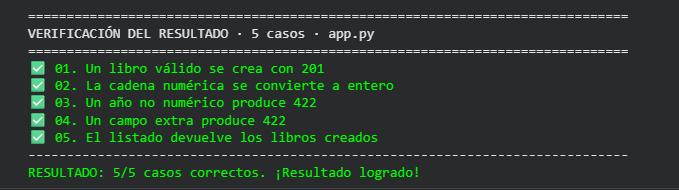